# Exploration de la source OpenWeather

## 1. Contexte et objectif du notebook

Après OpenSky, je passe à la deuxième source du projet : OpenWeather, qui donne les conditions météorologiques actuelles pour un point géographique précis (`https://api.openweathermap.org/data/2.5/weather`).

La logique d'appel est différente de celle d'OpenSky. Là où OpenSky renvoyait en un seul appel tous les avions présents sur une zone entière, OpenWeather fonctionne point par point : impossible d'interroger toute l'Europe météorologiquement en un seul appel, il faut demander la météo aéroport par aéroport. Le module d'ingestion météo boucle donc sur une liste fixe de dix hubs aéroportuaires européens (Paris CDG, Londres Heathrow, Francfort, Amsterdam, Madrid, Rome, Istanbul, Dublin, Munich, Barcelone) et effectue un appel par aéroport.

Je veux comprendre, comme pour OpenSky : combien de lignes cela représente, quelle est la fraîcheur des mesures, quels champs sont complets ou non, si les valeurs sont physiquement cohérentes, et quel volume ça représente sur la durée du projet.

Comme pour OpenSky, ces résultats ne sont pas figés : l'API renvoie les conditions météo au moment de la requête, donc relancer ce notebook plus tard donnera des valeurs différentes (température, vent, description du ciel...). Ce qui reste stable, c'est la structure des données et les règles de qualité identifiées ci-dessous.

In [1]:
import glob
import json
import os
import sys
import warnings
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import pandas as pd

# On se place à la racine du projet pour retrouver src/, config/ et le fichier .env
RACINE_PROJET = os.path.abspath(os.path.join(os.getcwd(), ".."))
if RACINE_PROJET not in sys.path:
    sys.path.insert(0, RACINE_PROJET)
os.chdir(RACINE_PROJET)

from src.ingestion.openweather_client import OpenWeatherClient

pd.set_option("display.max_columns", None)

C:\Users\jeann\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 2. Récupération et chargement des données

J'interroge le module d'ingestion météo pour les dix hubs aéroportuaires définis dans `HUBS_AEROPORTUAIRES` : chaque appel renvoie la météo actuelle pour un seul aéroport, donc dix appels HTTP au total pour cette capture.

La cellule ci-dessous appelle l'API OpenWeather en direct, puis sauvegarde le résultat dans `data/raw/`, comme pour OpenSky. En cas d'erreur (API indisponible, quota dépassé), je retombe sur le dernier fichier déjà collecté, pour que le notebook reste exécutable même hors connexion.

In [2]:
DOSSIER_DONNEES_BRUTES = os.path.join(RACINE_PROJET, "data", "raw")

try:
    client = OpenWeatherClient()
    donnees_brutes = client.recuperer_meteo_hubs_aeroportuaires()
    instant_collecte_utc = datetime.now(timezone.utc)
    chemin_fichier = client.sauvegarder_donnees_brutes(
        donnees_brutes, dossier=DOSSIER_DONNEES_BRUTES
    )
    print(f"Nouvel appel API réussi, données sauvegardées dans : {chemin_fichier}")
except Exception as erreur:
    print(f"Appel API impossible ({erreur}), réutilisation du dernier fichier disponible.")
    fichiers_disponibles = sorted(
        glob.glob(os.path.join(DOSSIER_DONNEES_BRUTES, "openweather_*.json"))
    )
    chemin_fichier = fichiers_disponibles[-1]
    instant_collecte_utc = datetime.fromtimestamp(
        os.path.getmtime(chemin_fichier), tz=timezone.utc
    )
    with open(chemin_fichier, encoding="utf-8") as fichier:
        donnees_brutes = json.load(fichier)
    print(f"Fichier réutilisé : {chemin_fichier}")

2026-08-25 11:41:53,486 - src.ingestion.openweather_client - INFO - Récupération de la météo pour Paris Charles-de-Gaulle (CDG).
2026-08-25 11:41:54,464 - src.ingestion.openweather_client - INFO - Appel à l'API OpenWeather réussi (code 200).
2026-08-25 11:41:54,469 - src.ingestion.openweather_client - INFO - Récupération de la météo pour Londres Heathrow (LHR).
2026-08-25 11:41:55,411 - src.ingestion.openweather_client - INFO - Appel à l'API OpenWeather réussi (code 200).
2026-08-25 11:41:55,416 - src.ingestion.openweather_client - INFO - Récupération de la météo pour Francfort (FRA).
2026-08-25 11:41:56,359 - src.ingestion.openweather_client - INFO - Appel à l'API OpenWeather réussi (code 200).
2026-08-25 11:41:56,364 - src.ingestion.openweather_client - INFO - Récupération de la météo pour Amsterdam Schiphol (AMS).
2026-08-25 11:41:57,275 - src.ingestion.openweather_client - INFO - Appel à l'API OpenWeather réussi (code 200).
2026-08-25 11:41:57,281 - src.ingestion.openweather_client

Nouvel appel API réussi, données sauvegardées dans : C:\Users\jeann\Documents\DataScientest\Projet Airlines\data\raw\openweather_20260825_114202.json


## 3. Combien de lignes obtient-on, et à quoi ressemblent les données une fois mises à plat ?

Chaque réponse d'OpenWeather est un objet JSON imbriqué (température et pression regroupées sous `main`, vent sous `wind`, etc.). Je mets chaque hub à plat en une seule ligne, avec les champs imbriqués renommés en notation pointée (`main.temp`, `wind.speed`...), pour obtenir un DataFrame directement exploitable.

In [3]:
lignes_meteo = []
for hub in donnees_brutes["hubs"]:
    ligne = pd.json_normalize(hub["meteo"]).iloc[0].to_dict()
    ligne["nom_aeroport"] = hub["nom_aeroport"]
    ligne["code_iata"] = hub["code_iata"]
    lignes_meteo.append(ligne)

df_meteo = pd.DataFrame(lignes_meteo)

colonnes_identification = ["nom_aeroport", "code_iata"]
colonnes_ordonnees = colonnes_identification + [
    colonne for colonne in df_meteo.columns if colonne not in colonnes_identification
]
df_meteo = df_meteo[colonnes_ordonnees]

print(f"Nombre de lignes (aéroports) : {len(df_meteo)}")
print(f"Nombre de colonnes : {df_meteo.shape[1]}")
df_meteo.head(10)

Nombre de lignes (aéroports) : 10
Nombre de colonnes : 30


,nom_aeroport,code_iata,weather,base,visibility,dt,timezone,id,name,cod,coord.lon,coord.lat,main.temp,main.feels_like,main.temp_min,main.temp_max,main.pressure,main.humidity,main.sea_level,main.grnd_level,wind.speed,wind.deg,clouds.all,sys.type,sys.id,sys.country,sys.sunrise,sys.sunset,rain.1h,wind.gust
0,Paris Charles-de-Gaulle,CDG,"[{'id': 804, 'main': 'Clouds', 'description': ...",stations,10000,1787650854,7200,2983073,Roissy-en-France,200,2.5479,49.0097,20.98,20.54,20.24,23.16,1011,54,1011,1002,2.06,0,99,1,6542,FR,1787633773,1787683688,NaN,NaN
1,Londres Heathrow,LHR,"[{'id': 803, 'main': 'Clouds', 'description': ...",stations,10000,1787650914,3600,7284876,Heathrow,200,-0.4543,51.4700,22.53,22.38,21.10,23.74,1013,59,1013,1008,6.69,80,53,1,1417,GB,1787634192,1787684709,NaN,NaN
2,Francfort,FRA,"[{'id': 501, 'main': 'Rain', 'description': 'p...",stations,10000,1787650915,7200,7290400,Airport Frankfurt Main,200,8.5622,50.0379,19.10,18.66,18.30,19.95,1014,61,1014,998,3.09,140,100,1,1265,DE,1787632206,1787682369,1.54,NaN
3,Amsterdam Schiphol,AMS,"[{'id': 800, 'main': 'Clear', 'description': '...",stations,10000,1787650916,7200,2747542,Schiphol,200,4.7639,52.3086,19.45,19.15,18.85,21.64,1015,65,1015,1015,5.14,70,0,1,1524,NL,1787632828,1787683569,NaN,NaN
4,Madrid Barajas,MAD,"[{'id': 804, 'main': 'Clouds', 'description': ...",stations,10000,1787650917,7200,3128832,Barajas,200,-3.5676,40.4983,22.44,22.25,21.40,23.31,1016,58,1016,943,5.14,230,100,1,6421,ES,1787636080,1787684315,NaN,NaN
5,Rome Fiumicino,FCO,"[{'id': 801, 'main': 'Clouds', 'description': ...",stations,10000,1787650918,7200,6693932,Focene,200,12.2389,41.8003,31.05,37.73,30.01,32.10,1012,70,1012,1011,8.23,160,19,1,6795,IT,1787632172,1787680638,NaN,13.89
6,Istanbul,IST,"[{'id': 800, 'main': 'Clear', 'description': '...",stations,10000,1787650919,10800,747793,Durusu,200,28.7519,41.2753,28.34,28.65,28.34,31.62,1016,48,1016,1008,7.15,40,0,2,2100075,TR,1787628252,1787676633,NaN,NaN
7,Dublin,DUB,"[{'id': 502, 'main': 'Rain', 'description': 'f...",stations,10000,1787650920,3600,3316325,Coultry,200,-6.2701,53.4213,16.86,16.43,16.62,17.62,1014,70,1014,1005,5.14,90,98,1,1565,IE,1787635325,1787686368,5.57,NaN
8,Munich,MUC,"[{'id': 501, 'main': 'Rain', 'description': 'p...",stations,10000,1787650921,7200,2925470,Franzheim,200,11.7861,48.3538,15.94,15.65,15.62,16.97,1014,79,1014,958,4.63,260,100,1,1267,DE,1787631628,1787681399,1.78,NaN
9,Barcelone,BCN,"[{'id': 803, 'main': 'Clouds', 'description': ...",stations,10000,1787650922,7200,6544426,El Mas Blau,200,2.0833,41.2974,30.34,29.74,30.01,31.78,1012,37,1012,1005,1.03,310,59,1,6398,ES,1787634655,1787683029,NaN,NaN


**Ce que ça donne** : cette capture donne 10 lignes (une par aéroport) et 30 colonnes une fois les champs imbriqués mis à plat. On retrouve la structure documentée par OpenWeather : `main.*` pour la température et la pression, `wind.*` pour le vent, `coord.*` pour les coordonnées, `sys.*` pour le pays et les horaires de lever/coucher du soleil. Le champ `weather` reste une liste (traité juste après), et deux champs optionnels apparaissent seulement pour certains aéroports : `rain.1h` (cumul de pluie sur la dernière heure) et `wind.gust` (rafales), qui ne sont renvoyés par l'API que lorsque le phénomène est effectivement mesuré.

Le champ `weather` reste une liste de dictionnaires après la mise à plat (OpenWeather peut en théorie renvoyer plusieurs conditions simultanées, même si un seul élément est présent en pratique pour ce endpoint). J'en extrais la description textuelle dans une colonne dédiée, plus simple à manipuler pour la suite.

In [4]:
df_meteo["description_ciel"] = df_meteo["weather"].apply(
    lambda conditions: conditions[0]["description"] if conditions else None
)
df_meteo = df_meteo.drop(columns=["weather"])

df_meteo[["nom_aeroport", "code_iata", "description_ciel", "main.temp"]]

,nom_aeroport,code_iata,description_ciel,main.temp
0,Paris Charles-de-Gaulle,CDG,couvert,20.98
1,Londres Heathrow,LHR,nuageux,22.53
2,Francfort,FRA,pluie modérée,19.10
3,Amsterdam Schiphol,AMS,ciel dégagé,19.45
4,Madrid Barajas,MAD,couvert,22.44
5,Rome Fiumicino,FCO,peu nuageux,31.05
6,Istanbul,IST,ciel dégagé,28.34
7,Dublin,DUB,forte pluie,16.86
8,Munich,MUC,pluie modérée,15.94
9,Barcelone,BCN,nuageux,30.34


## 4. Quelle est la fraîcheur des mesures météo ?

Le champ `dt` indique l'horodatage (UTC) auquel la station météo la plus proche a mesuré les conditions renvoyées par l'API. Ce n'est pas forcément l'instant exact de ma requête : OpenWeather agrège des relevés de stations au sol, rafraîchis en moyenne toutes les dix minutes côté fournisseur (voir `docs/rendu1_decouverte_exploration.md`). Je calcule l'écart entre `dt` et l'instant de ma collecte pour vérifier ce délai.

In [5]:
df_meteo["instant_mesure_utc"] = df_meteo["dt"].apply(
    lambda ts: datetime.fromtimestamp(ts, tz=timezone.utc)
)
df_meteo["age_donnee_secondes"] = (
    instant_collecte_utc - df_meteo["instant_mesure_utc"]
).dt.total_seconds()

print("Distribution de l'âge des mesures météo (en secondes) :")
print(df_meteo["age_donnee_secondes"].describe())
print()
print(df_meteo[["nom_aeroport", "instant_mesure_utc", "age_donnee_secondes"]])

Distribution de l'âge des mesures météo (en secondes) :
count    10.000000
mean     11.327977
std      20.402614
min       0.927977
25%       3.177977
50%       5.427977
75%       7.677977
max      68.927977
Name: age_donnee_secondes, dtype: float64

              nom_aeroport        instant_mesure_utc  age_donnee_secondes
0  Paris Charles-de-Gaulle 2026-08-25 09:40:54+00:00            68.927977
1         Londres Heathrow 2026-08-25 09:41:54+00:00             8.927977
2                Francfort 2026-08-25 09:41:55+00:00             7.927977
3       Amsterdam Schiphol 2026-08-25 09:41:56+00:00             6.927977
4           Madrid Barajas 2026-08-25 09:41:57+00:00             5.927977
5           Rome Fiumicino 2026-08-25 09:41:58+00:00             4.927977
6                 Istanbul 2026-08-25 09:41:59+00:00             3.927977
7                   Dublin 2026-08-25 09:42:00+00:00             2.927977
8                   Munich 2026-08-25 09:42:01+00:00             1.927977
9        

**Ce que ça donne** : sur cette capture, les mesures ont entre 1 et 69 secondes d'écart avec l'instant de ma requête (moyenne autour de 11 secondes), donc bien plus fraîches que le cycle de rafraîchissement d'environ 10 minutes annoncé par OpenWeather pour les données courantes (voir `docs/rendu1_decouverte_exploration.md`). L'écart croît régulièrement de Barcelone (dernier hub interrogé) à Paris (premier hub interrogé), ce qui correspond exactement à l'ordre et au rythme des appels HTTP successifs : `dt` semble donc être recalculé à chaque requête plutôt que refléter la dernière mesure d'une station au sol figée pendant 10 minutes. Contrairement à OpenSky, où l'écart pouvait varier de moins d'une seconde à plusieurs heures selon la couverture des récepteurs ADS-B, la fraîcheur ici est très bonne et homogène d'un aéroport à l'autre.

## 5. Quels champs sont systématiquement vides ou nuls, et dans quelle proportion ?

Comme pour OpenSky, je calcule le taux de complétude de chaque colonne pour repérer les champs qui posent problème, avant d'aller vérifier s'il s'agit d'un vrai problème de qualité ou d'une absence structurelle (un champ qui n'apparaît que dans certaines conditions météo, par exemple).

wind.gust               10.0
rain.1h                 30.0
nom_aeroport           100.0
description_ciel       100.0
sys.sunset             100.0
sys.sunrise            100.0
sys.country            100.0
sys.id                 100.0
sys.type               100.0
clouds.all             100.0
wind.deg               100.0
wind.speed             100.0
main.grnd_level        100.0
main.sea_level         100.0
main.humidity          100.0
main.pressure          100.0
main.temp_max          100.0
main.temp_min          100.0
main.feels_like        100.0
main.temp              100.0
coord.lat              100.0
coord.lon              100.0
cod                    100.0
name                   100.0
id                     100.0
timezone               100.0
dt                     100.0
visibility             100.0
base                   100.0
code_iata              100.0
instant_mesure_utc     100.0
age_donnee_secondes    100.0
dtype: float64


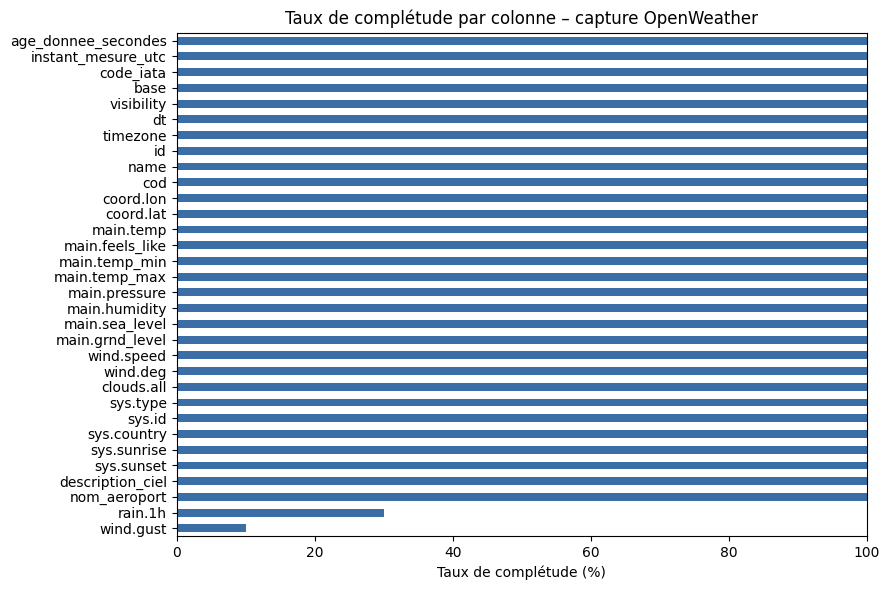

In [6]:
taux_completude = (df_meteo.notna().mean() * 100).sort_values()
print(taux_completude.round(2))

fig, ax = plt.subplots(figsize=(9, 6))
taux_completude.plot(kind="barh", ax=ax, color="#3b6ea5")
ax.set_xlabel("Taux de complétude (%)")
ax.set_title("Taux de complétude par colonne – capture OpenWeather")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

**Ce que ça donne** : 28 des 30 colonnes sont complètes à 100 %. Seules deux colonnes ont des valeurs manquantes, et dans les deux cas la cause est structurelle plutôt qu'un vrai problème de qualité : `rain.1h` n'est renseigné que pour Francfort, Dublin et Munich (30 %), les trois seuls aéroports où il pleuvait réellement au moment de la capture, et `wind.gust` n'est renseigné que pour Rome Fiumicino (10 %), seul aéroport où l'API a mesuré une rafale significative. OpenWeather n'inclut ces champs dans sa réponse que lorsque le phénomène est présent, au lieu de renvoyer systématiquement une valeur à zéro : l'absence de valeur signifie donc "pas de pluie" ou "pas de rafale notable", pas une donnée manquante à traiter comme une anomalie. C'est le même type de non-complétude structurelle que celle observée sur `baro_altitude` avec OpenSky (liée au statut au sol), à ceci près qu'ici, elle est directement documentée par le comportement de l'API plutôt que déduite par croisement de colonnes.

## 6. Les valeurs sont-elles physiquement cohérentes ?

Je vérifie que chaque variable reste dans des bornes physiquement plausibles : température entre -60 et 55 degrés (records mondiaux), humidité entre 0 et 100 %, pression atmosphérique entre 870 et 1085 hPa (records mondiaux), vitesse du vent positive, et visibilité entre 0 et 10 000 mètres (10 km étant le plafond renvoyé par l'API, qui ne distingue pas au-delà).

In [7]:
nb_temperature_hors_bornes = (
    (df_meteo["main.temp"] < -60) | (df_meteo["main.temp"] > 55)
).sum()
nb_humidite_hors_bornes = (
    (df_meteo["main.humidity"] < 0) | (df_meteo["main.humidity"] > 100)
).sum()
nb_pression_hors_bornes = (
    (df_meteo["main.pressure"] < 870) | (df_meteo["main.pressure"] > 1085)
).sum()
nb_vent_negatif = (df_meteo["wind.speed"] < 0).sum()
nb_visibilite_hors_bornes = (
    (df_meteo["visibility"] < 0) | (df_meteo["visibility"] > 10000)
).sum()

print(f"Températures hors bornes [-60, 55] °C : {nb_temperature_hors_bornes} ligne(s)")
print(f"Humidités hors bornes [0, 100] % : {nb_humidite_hors_bornes} ligne(s)")
print(f"Pressions hors bornes [870, 1085] hPa : {nb_pression_hors_bornes} ligne(s)")
print(f"Vitesses de vent négatives : {nb_vent_negatif} ligne(s)")
print(f"Visibilités hors bornes [0, 10000] m : {nb_visibilite_hors_bornes} ligne(s)")
print()
print("Statistiques descriptives des variables météo principales :")
df_meteo[
    ["main.temp", "main.humidity", "main.pressure", "wind.speed", "visibility"]
].describe()

Températures hors bornes [-60, 55] °C : 0 ligne(s)
Humidités hors bornes [0, 100] % : 0 ligne(s)
Pressions hors bornes [870, 1085] hPa : 0 ligne(s)
Vitesses de vent négatives : 0 ligne(s)
Visibilités hors bornes [0, 10000] m : 0 ligne(s)

Statistiques descriptives des variables météo principales :


,main.temp,main.humidity,main.pressure,wind.speed,visibility
count,10.000000,10.000000,10.000000,10.0000,10.0
mean,22.703000,60.100000,1013.700000,4.8300,10000.0
std,5.439385,12.022664,1.702939,2.2576,0.0
min,15.940000,37.000000,1011.000000,1.0300,10000.0
25%,19.187500,55.000000,1012.250000,3.4750,10000.0
50%,21.710000,60.000000,1014.000000,5.1400,10000.0
75%,26.887500,68.750000,1014.750000,6.3025,10000.0
max,31.050000,79.000000,1016.000000,8.2300,10000.0


**Ce que ça donne** : aucune valeur hors bornes sur cette capture, pour aucune des cinq variables vérifiées. Les températures vont de 15,94 à 31,05 degrés, l'humidité de 37 à 79 %, la pression de 1011 à 1016 hPa (un intervalle très resserré, cohérent avec une zone de haute pression généralisée sur l'Europe ce jour-là), le vent de 1,03 à 8,23 m/s, et la visibilité est au maximum (10 000 m) pour les dix aéroports. Ce dernier point est à garder en tête pour la suite : l'API plafonne visiblement la visibilité à 10 km, donc cette colonne ne permettra pas de distinguer une bonne visibilité d'une excellente visibilité, seulement de détecter les cas de visibilité réduite (brouillard, tempête) si elle redescend un jour sous ce plafond.

## 7. Quelle est la répartition des conditions météo par aéroport ?

Je compare la température et la vitesse du vent entre les dix hubs, pour voir si des écarts notables apparaissent entre le nord et le sud de l'Europe au moment de cette capture.

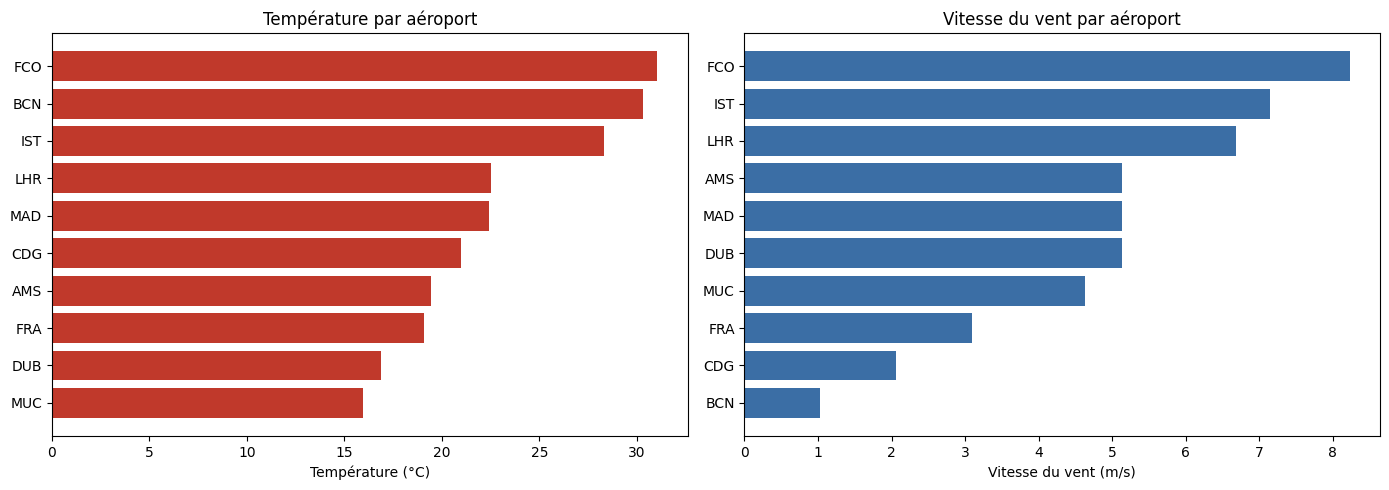

,nom_aeroport,code_iata,description_ciel,main.temp,wind.speed
0,Paris Charles-de-Gaulle,CDG,couvert,20.98,2.06
1,Londres Heathrow,LHR,nuageux,22.53,6.69
2,Francfort,FRA,pluie modérée,19.10,3.09
3,Amsterdam Schiphol,AMS,ciel dégagé,19.45,5.14
4,Madrid Barajas,MAD,couvert,22.44,5.14
5,Rome Fiumicino,FCO,peu nuageux,31.05,8.23
6,Istanbul,IST,ciel dégagé,28.34,7.15
7,Dublin,DUB,forte pluie,16.86,5.14
8,Munich,MUC,pluie modérée,15.94,4.63
9,Barcelone,BCN,nuageux,30.34,1.03


In [8]:
df_tri_temperature = df_meteo.sort_values("main.temp", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(df_tri_temperature["code_iata"], df_tri_temperature["main.temp"], color="#c0392b")
axes[0].set_xlabel("Température (°C)")
axes[0].set_title("Température par aéroport")
axes[0].invert_yaxis()

df_tri_vent = df_meteo.sort_values("wind.speed", ascending=False)
axes[1].barh(df_tri_vent["code_iata"], df_tri_vent["wind.speed"], color="#3b6ea5")
axes[1].set_xlabel("Vitesse du vent (m/s)")
axes[1].set_title("Vitesse du vent par aéroport")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

df_meteo[["nom_aeroport", "code_iata", "description_ciel", "main.temp", "wind.speed"]]

**Ce que ça donne** : un net gradient nord-sud apparaît sur cette capture. Rome (31,05°C) et Barcelone (30,34°C) sont les plus chauds, suivis d'Istanbul (28,34°C), tandis que Munich (15,94°C) et Dublin (16,86°C) sont les plus frais, avec un écart de plus de 15 degrés entre les extrêmes. Le vent ne suit pas la même logique géographique : Rome (8,23 m/s) et Istanbul (7,15 m/s) sont les plus venteux, alors que Barcelone (1,03 m/s), Paris (2,06 m/s) et Francfort (3,09 m/s) sont les plus calmes, sans lien direct avec la latitude. Ce type d'écart entre aéroports est précisément ce qu'on veut capturer comme feature pour la prédiction de retard : une même compagnie peut décoller sans encombre d'un aéroport calme et subir un retard à l'arrivée sur un aéroport plus venteux ou pluvieux.

## 8. Quels types de données par colonne ?

Je vérifie que les types Python correspondent à ce qu'on attend pour chaque champ.

In [9]:
print("Types de données par colonne :")
print(df_meteo.dtypes)

Types de données par colonne :
nom_aeroport                        object
code_iata                           object
base                                object
visibility                           int64
dt                                   int64
timezone                             int64
id                                   int64
name                                object
cod                                  int64
coord.lon                          float64
coord.lat                          float64
main.temp                          float64
main.feels_like                    float64
main.temp_min                      float64
main.temp_max                      float64
main.pressure                        int64
main.humidity                        int64
main.sea_level                       int64
main.grnd_level                      int64
wind.speed                         float64
wind.deg                             int64
clouds.all                           int64
sys.type               

**Ce que ça donne** : les types sont cohérents avec ce qu'on attend, avec un mélange d'`int64` (identifiants, angles, codes) et de `float64` (température, vent, pluie) qui reflète simplement la précision renvoyée par l'API pour chaque champ, plus quelques colonnes `object` pour le texte (`name`, `description_ciel`, `sys.country`) et une colonne `datetime64[ns, UTC]` pour l'horodatage de mesure que j'ai calculé moi-même. Rien d'aberrant à signaler ici.

## 9. Quel volume de données cela représente-t-il ?

Je calcule la taille du fichier JSON de cette capture (dix aéroports), puis je la compare à celle d'OpenSky, avant de projeter le volume total sur la durée du projet selon différentes fréquences de collecte.

In [10]:
taille_octets = os.path.getsize(chemin_fichier)
taille_ko = taille_octets / 1024

print(f"Nombre de lignes de cette capture : {len(df_meteo)}")
print(f"Taille du fichier JSON brut : {taille_octets} octets ({taille_ko:.1f} Ko)")
print()

DUREE_PROJET_JOURS = 14
print(f"Projection sur {DUREE_PROJET_JOURS} jours de collecte, selon la fréquence choisie :")
for frequence_minutes in (10, 30, 60):
    nb_captures = DUREE_PROJET_JOURS * 24 * 60 / frequence_minutes
    volume_total_mo = nb_captures * taille_octets / (1024 * 1024)
    print(
        f"  - Toutes les {frequence_minutes} min : {nb_captures:.0f} captures, "
        f"environ {volume_total_mo:.2f} Mo au total"
    )

Nombre de lignes de cette capture : 10
Taille du fichier JSON brut : 11567 octets (11.3 Ko)

Projection sur 14 jours de collecte, selon la fréquence choisie :
  - Toutes les 10 min : 2016 captures, environ 22.24 Mo au total
  - Toutes les 30 min : 672 captures, environ 7.41 Mo au total
  - Toutes les 60 min : 336 captures, environ 3.71 Mo au total


**Ce que ça donne** : une capture pour les dix hubs pèse 11,3 Ko, sans commune mesure avec le mégaoctet d'une capture OpenSky sur toute l'Europe. Sur 14 jours, même une collecte toutes les 10 minutes (le rythme de rafraîchissement réel des données OpenWeather, donc la fréquence la plus fine qui ait un intérêt) ne représenterait qu'environ 22 Mo, contre plusieurs gigaoctets pour OpenSky à fréquence comparable. Cet écart s'explique directement par la différence d'architecture des deux API : OpenSky renvoie des milliers de lignes par appel (tous les avions d'une zone), OpenWeather en renvoie une seule par appel (un point précis) multipliée par le nombre de hubs suivis. La contrainte sur cette source n'est donc pas le volume de stockage, mais le nombre d'appels HTTP à effectuer si on voulait suivre davantage d'aéroports.

## 10. Rapport de profiling automatisé (ydata-profiling)

Comme pour OpenSky, je complète cette exploration ciblée par un rapport `ydata-profiling` exhaustif, qui couvre systématiquement chaque colonne. Avec seulement dix lignes, ce rapport a surtout une valeur de vérification structurelle (types, complétude) plutôt que statistique (les distributions et corrélations calculées sur dix points ont peu de portée) : c'est une conséquence directe de l'architecture point par point d'OpenWeather, à la différence d'OpenSky qui renvoie plusieurs milliers de lignes par capture.

In [11]:
from ydata_profiling import ProfileReport

DOSSIER_PROFILING = os.path.join(RACINE_PROJET, "data", "profiling_reports")
os.makedirs(DOSSIER_PROFILING, exist_ok=True)
chemin_rapport = os.path.join(DOSSIER_PROFILING, "openweather_profiling_report.html")

warnings.filterwarnings("ignore", category=FutureWarning, module="ydata_profiling")

rapport = ProfileReport(
    df_meteo,
    title="Rapport de profiling - OpenWeather",
    explorative=True,
    progress_bar=False,
)
rapport.to_file(chemin_rapport)

print(f"Rapport de profiling généré : {chemin_rapport}")

Rapport de profiling généré : C:\Users\jeann\Documents\DataScientest\Projet Airlines\data\profiling_reports\openweather_profiling_report.html


## 11. Synthèse et conclusions

**Complétude générale** : sur cette capture, 28 des 30 champs sont complets à 100 %. Les deux seuls champs avec des valeurs manquantes (`rain.1h`, `wind.gust`) sont structurellement absents quand le phénomène correspondant n'est pas mesuré, exactement comme OpenWeather le documente : rien à traiter comme une anomalie, seulement une règle de nettoyage à prévoir (remplacer l'absence par zéro plutôt que par une valeur indéterminée).

**Anomalies repérées** : aucune. Les cinq variables vérifiées (température, humidité, pression, vent, visibilité) restent toutes dans des bornes physiquement plausibles sur cette capture. Un point de vigilance identifié plutôt qu'une anomalie : la visibilité est plafonnée à 10 000 mètres pour les dix aéroports, ce qui limite la capacité de cette colonne à distinguer les bonnes conditions entre elles, mais reste utile pour détecter une dégradation en dessous de ce plafond.

**Fraîcheur** : sur cette capture, les mesures ont entre 1 et 69 secondes d'écart avec l'instant de la requête, un délai très court et homogène d'un aéroport à l'autre, plus fin que le cycle de rafraîchissement d'environ 10 minutes annoncé par OpenWeather pour les données courantes. Contrairement à OpenSky, il n'y a pas ici de risque de récupérer une donnée vieille de plusieurs heures.

**Volumétrie** : une capture des dix hubs pèse 11,3 Ko, plusieurs ordres de grandeur en dessous d'une capture OpenSky. Cette différence n'est pas un hasard mais une conséquence directe de l'architecture des deux API (zone géographique contre point géographique), à garder en tête pour dimensionner la fréquence de collecte du pipeline final.

**Conclusions pour la suite du projet** : la structure obtenue (une ligne par aéroport et par capture, avec température, vent, pluie, pression et description du ciel) est directement exploitable comme dimension météo dans le futur schéma en étoile. Les règles de nettoyage à prévoir en Phase 2 sont désormais claires : remplacer l'absence de `rain.1h` et `wind.gust` par zéro, retirer la colonne `weather` brute au profit de `description_ciel`, et documenter le plafond de visibilité à 10 km. Contrairement à OpenSky, la fraîcheur et la cohérence des valeurs ne posent pas de difficulté particulière sur cette source ; le point d'attention principal reste la faible volumétrie par capture, qui suppose de multiplier les collectes dans le temps pour construire un historique météo réellement exploitable par aéroport.